# Training CNN Pengenalan Dadu — Monopoly Lite with CNN Dice Recognition on FPGA

Notebook ini melatih CNN kecil yang membaca **angka dadu (1–6)** dari foto, sesuai rancangan sistem
(*kamera → grayscale → resize → CNN → angka + confidence → FSM game*), lalu mengekspor bobot **INT8
lengkap dengan skala kuantisasinya** untuk diimplementasikan di Verilog (DE10-Standard).

**Dataset (Kaggle):** [`josephnelson/six-sided-dice-images-and-bounding-boxes`](https://www.kaggle.com/datasets/josephnelson/six-sided-dice-images-and-bounding-boxes)
— foto dadu dengan anotasi kotak format Pascal VOC XML, label `1`–`6` (lisensi CC0-1.0 menurut keluaran Kaggle CLI).

**Ketentuan resolusi:** input CNN minimal **32 × 32 piksel** (default 32 × 32, grayscale 1 kanal).
Dadu yang di foto aslinya lebih kecil dari 32 px dibuang supaya tidak ada gambar hasil upscale berlebihan.

**Alur:**
1. Unduh dataset dari Kaggle
2. Potong (crop) tiap dadu dari anotasi XML → persegi → grayscale → resize 32×32
3. Split train/val/test **per foto** (dadu dari foto yang sama tidak boleh terpisah antar split)
4. Latih CNN kecil (tanpa BatchNorm, hanya Conv + ReLU + MaxPool + Dense → mudah ke Verilog)
5. Evaluasi: akurasi, confusion matrix, dan analisis confidence
6. Kuantisasi INT8 + model integer "golden" di NumPy (acuan untuk testbench Verilog)
7. Ekspor `.mem`, `params.vh`, test vector, lalu unduh ZIP

> Runtime **CPU sudah cukup** (modelnya sekitar 9 ribu parameter).

## 1. Setup

In [1]:
!pip -q install kagglehub

In [2]:
import os, glob, json, math, random, shutil
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from numpy.lib.stride_tricks import sliding_window_view

# ===================== KONFIGURASI =====================
SEED         = 42
IMG_SIZE     = 32     # resolusi input CNN. Minimal 32. (32 paling hemat resource FPGA)
MIN_CROP_PX  = 32     # dadu di foto asli yang lebih kecil dari ini dibuang
MARGIN       = 0.15   # tambahan area di sekeliling dadu saat di-crop
EPOCHS       = 150
BATCH        = 64
TARGET_ACC   = 0.98   # target akurasi pada dadu yang DITERIMA (sisanya = lempar ulang)
OUT_DIR      = "export"
# ========================================================

assert IMG_SIZE >= 32, "IMG_SIZE minimal 32"
keras.utils.set_random_seed(SEED)
random.seed(SEED); np.random.seed(SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Unduh dataset dari Kaggle

Kalau muncul permintaan login, masukkan **username Kaggle** dan **API token**
(Kaggle → Settings → API → *Create New Token*). Ukuran unduhan sekitar 390 MB.

In [3]:
import kagglehub
try:
    DATA_ROOT = kagglehub.dataset_download("josephnelson/six-sided-dice-images-and-bounding-boxes")
except Exception as e:
    print("Perlu login Kaggle:", e)
    kagglehub.login()
    DATA_ROOT = kagglehub.dataset_download("josephnelson/six-sided-dice-images-and-bounding-boxes")
print("Dataset di:", DATA_ROOT)

100%|██████████| 388M/388M [00:07<00:00, 55.9MB/s]

Extracting files...


Dataset di: /root/.cache/kagglehub/datasets/josephnelson/six-sided-dice-images-and-bounding-boxes/versions/1


In [4]:
import xml.etree.ElementTree as ET
from collections import Counter

IMG_EXT = (".jpg", ".jpeg", ".png")
img_index = {}                                    # nama file -> path lengkap
for dp, _, fns in os.walk(DATA_ROOT):
    for fn in fns:
        if fn.lower().endswith(IMG_EXT):
            img_index[fn] = os.path.join(dp, fn)
XML_PATHS = sorted(glob.glob(os.path.join(DATA_ROOT, "**", "*.xml"), recursive=True))
print(len(img_index), "foto |", len(XML_PATHS), "file anotasi XML")

LABELS = ("1", "2", "3", "4", "5", "6")
name_counter = Counter()

def find_image(xml_root, xml_path):
    fn = (xml_root.findtext("filename") or "").strip()
    if fn in img_index:
        return img_index[fn]
    stem = os.path.splitext(os.path.basename(xml_path))[0]
    for ext in IMG_EXT:
        if stem + ext in img_index:
            return img_index[stem + ext]
    return None

def read_voc(xml_path):
    """Kembalikan (path_gambar, [(kelas 0..5, xmin, ymin, xmax, ymax), ...]).
    Label <name> '1'..'6' -> kelas 0..5 (kelas = angka dadu - 1)."""
    root = ET.parse(xml_path).getroot()
    boxes = []
    for obj in root.findall("object"):
        name = (obj.findtext("name") or "").strip()
        name_counter[name] += 1
        bb = obj.find("bndbox")
        if bb is None or name not in LABELS:
            continue
        x0, y0, x1, y1 = [float(bb.findtext(t)) for t in ("xmin", "ymin", "xmax", "ymax")]
        boxes.append((int(name) - 1, x0, y0, x1, y1))
    return find_image(root, xml_path), boxes

359 foto | 359 file anotasi XML


### Cek visual anotasi
Pastikan kotak pas di dadu dan angka yang tertulis sesuai jumlah titik pada dadu.
Nama label yang ditemukan di seluruh XML dicetak di sel berikutnya (harus `1`–`6`).

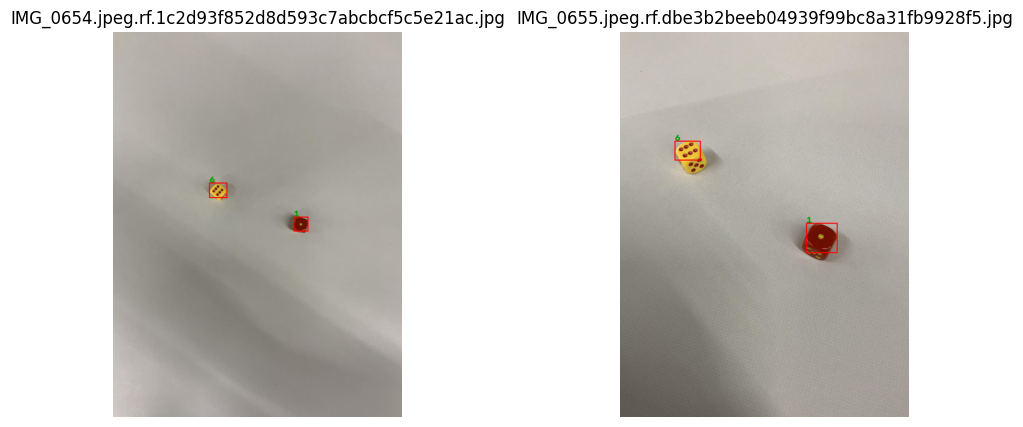

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
shown = 0
for xp in XML_PATHS:
    path, boxes = read_voc(xp)
    if path is None or not boxes:
        continue
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    t = max(2, W // 300)
    for c, x0, y0, x1, y1 in boxes:
        cv2.rectangle(img, (int(x0), int(y0)), (int(x1), int(y1)), (255, 0, 0), t)
        cv2.putText(img, str(c + 1), (int(x0), max(int(y0) - 5, 20)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(1.0, W / 1000), (0, 160, 0), t)
    axes[shown].imshow(img); axes[shown].axis("off"); axes[shown].set_title(os.path.basename(path))
    shown += 1
    if shown == 2:
        break
plt.show()

## 3. Potong tiap dadu → persegi → grayscale → resize

Tiap dadu di-crop **persegi** (sisi terpanjang kotak + margin) agar tidak gepeng, diubah ke grayscale, lalu di-resize ke
`IMG_SIZE × IMG_SIZE` dengan `INTER_AREA`. Ini meniru prapemrosesan di FPGA (grayscale + crop + resize).

In [6]:
def square_crop(gray, xc, yc, side):
    H, W = gray.shape
    s = int(round(side))
    x0 = int(round(xc - s / 2)); y0 = int(round(yc - s / 2))
    x1, y1 = x0 + s, y0 + s
    pl, pt = max(0, -x0), max(0, -y0)
    pr, pb = max(0, x1 - W), max(0, y1 - H)
    crop = gray[max(y0, 0):min(y1, H), max(x0, 0):min(x1, W)]
    if crop.size == 0:
        return None
    if pl or pt or pr or pb:
        crop = cv2.copyMakeBorder(crop, pt, pb, pl, pr, cv2.BORDER_REPLICATE)
    return crop

def build_crops():
    X, y, g = [], [], []
    small = bad = no_img = 0
    for gi, xp in enumerate(XML_PATHS):
        path, boxes = read_voc(xp)
        if path is None:
            no_img += 1; continue
        img = cv2.imread(path)
        if img is None:
            no_img += 1; continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        for c, x0, y0, x1, y1 in boxes:
            bw, bh = x1 - x0, y1 - y0
            if bw <= 0 or bh <= 0:
                bad += 1; continue
            if min(bw, bh) < MIN_CROP_PX:
                small += 1; continue
            crop = square_crop(gray, (x0 + x1) / 2, (y0 + y1) / 2, max(bw, bh) * (1 + MARGIN))
            if crop is None:
                bad += 1; continue
            X.append(cv2.resize(crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
            y.append(c); g.append(gi)
    print("label ditemukan di XML:", dict(name_counter))
    print(f"dadu dipakai: {len(X)} | dibuang (< {MIN_CROP_PX}px): {small} | "
          f"kotak tidak valid: {bad} | XML tanpa foto: {no_img}")
    return np.array(X, dtype=np.uint8)[..., None], np.array(y, dtype=np.int64), np.array(g)

X, y, groups = build_crops()
print("X:", X.shape, X.dtype, "| jumlah per kelas (sisi 1..6):", np.bincount(y, minlength=6))

label ditemukan di XML: {'1': 147, '6': 215, '4': 182, '2': 137, '3': 195, '5': 95}
dadu dipakai: 964 | dibuang (< 32px): 3 | kotak tidak valid: 0 | XML tanpa foto: 0
X: (964, 32, 32, 1) uint8 | jumlah per kelas (sisi 1..6): [143 137 195 182  95 212]


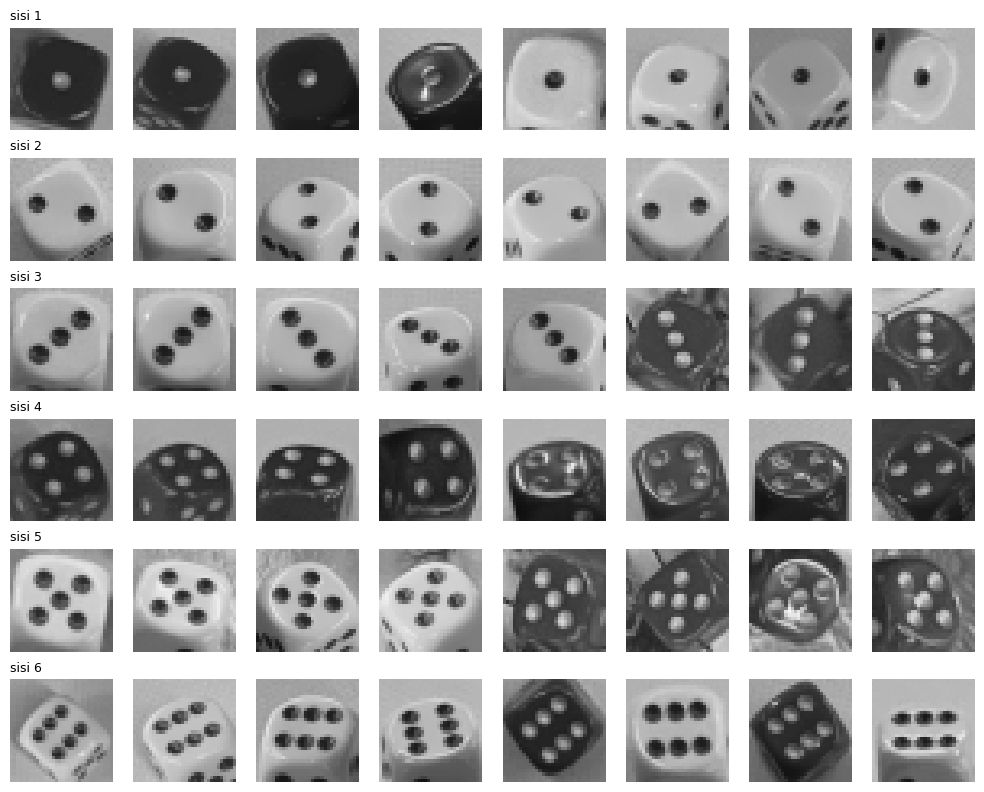

In [7]:
# Cek visual: 8 contoh per kelas (baris = sisi dadu 1..6)
fig, axes = plt.subplots(6, 8, figsize=(10, 8))
for k in range(6):
    idx = np.where(y == k)[0][:8]
    for j in range(8):
        ax = axes[k, j]; ax.axis("off")
        if j < len(idx):
            ax.imshow(X[idx[j], :, :, 0], cmap="gray", vmin=0, vmax=255)
    axes[k, 0].set_title(f"sisi {k+1}", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 4. Split train / val / test (per foto)

Dadu dari **foto yang sama** tidak boleh terpisah ke split berbeda (latar dan pencahayaannya mirip,
sehingga akurasi bisa terlihat terlalu bagus).

In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trval, te_idx = next(gss.split(X, y, groups=groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_rel, va_rel = next(gss2.split(X[trval], y[trval], groups=groups[trval]))
tr_idx, va_idx = trval[tr_rel], trval[va_rel]

X_tr, y_tr = X[tr_idx], y[tr_idx]
X_va, y_va = X[va_idx], y[va_idx]
X_te, y_te = X[te_idx], y[te_idx]
for name, yy in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{name:5s} n={len(yy):4d}  per kelas={np.bincount(yy, minlength=6)}")
assert len(np.unique(y_tr)) == 6, "Ada kelas yang tidak muncul di data train"

cw = compute_class_weight("balanced", classes=np.arange(6), y=y_tr)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("class_weight:", {k: round(v, 2) for k, v in class_weight.items()})

train n= 734  per kelas=[107 105 150 136  66 170]
val   n= 131  per kelas=[19 17 28 31 17 19]
test  n=  99  per kelas=[17 15 17 15 12 23]
class_weight: {0: 1.14, 1: 1.17, 2: 0.82, 3: 0.9, 4: 1.85, 5: 0.72}


## 5. Model CNN (ramah FPGA)

- Input **32×32×1**, nilai piksel mentah 0–255 (skala 1/255 ada di dalam model, jadi FPGA cukup memberi piksel 8-bit)
- Conv 3×3 (valid) + ReLU, MaxPool 2×2, tiga tahap — **tanpa BatchNorm dan tanpa padding** supaya hardware sederhana
- Dense 6 kelas (logits). Confidence dihitung dari selisih logit teratas pada tahap INT8

Augmentasi (rotasi bebas, flip, geser, zoom, kecerahan, kontras, noise) hanya dipakai saat training.

In [9]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5, fill_mode="reflect"),          # +-180 derajat
    layers.RandomTranslation(0.08, 0.08, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
    layers.RandomBrightness(0.25, value_range=(0, 255)),
    layers.RandomContrast(0.25),
], name="augment")

def make_ds(Xa, ya, train):
    ds = tf.data.Dataset.from_tensor_slices((Xa.astype("float32"), ya))
    if train:
        ds = ds.shuffle(len(Xa), seed=SEED).batch(BATCH)
        def _aug(a, b):
            a = augment(a, training=True)
            a = a + tf.random.normal(tf.shape(a), stddev=4.0)        # noise sensor
            return tf.clip_by_value(a, 0.0, 255.0), b
        ds = ds.map(_aug, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.batch(BATCH)
    return ds.prefetch(tf.data.AUTOTUNE)

def build_model(S):
    inp = keras.Input((S, S, 1), name="pixels")                  # 0..255
    x = layers.Rescaling(1 / 255.0, name="rescale")(inp)
    x = layers.Conv2D(8, 3, activation="relu", padding="valid", name="conv1")(x)
    x = layers.MaxPooling2D(2, name="pool1")(x)
    x = layers.Conv2D(16, 3, activation="relu", padding="valid", name="conv2")(x)
    x = layers.MaxPooling2D(2, name="pool2")(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="valid", name="conv3")(x)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dropout(0.3, name="drop")(x)
    out = layers.Dense(6, name="dense")(x)                        # logits
    return keras.Model(inp, out, name="dice_cnn")

model = build_model(IMG_SIZE)
model.summary()

Model: "dice_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pixels (InputLayer)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 30, 30, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 15, 15, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 13, 13, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 6, 6, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,966 (35.02 KB)

 Trainable params: 8,966 (35.02 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Training

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=20, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, min_lr=1e-5),
]
history = model.fit(
    make_ds(X_tr, y_tr, True),
    validation_data=make_ds(X_va, y_va, False),
    epochs=EPOCHS, callbacks=callbacks, class_weight=class_weight, verbose=2,
)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Akurasi"); ax[1].legend()
plt.tight_layout(); plt.show()

Epoch 1/150
12/12 - 4s - 335ms/step - accuracy: 0.1526 - loss: 1.7921 - val_accuracy: 0.2443 - val_loss: 1.7736 - learning_rate: 0.0010
Epoch 2/150
12/12 - 1s - 74ms/step - accuracy: 0.2248 - loss: 1.7780 - val_accuracy: 0.2443 - val_loss: 1.7509 - learning_rate: 0.0010
Epoch 3/150
12/12 - 1s - 55ms/step - accuracy: 0.2643 - loss: 1.7559 - val_accuracy: 0.2824 - val_loss: 1.7188 - learning_rate: 0.0010
Epoch 4/150
12/12 - 1s - 54ms/step - accuracy: 0.1744 - loss: 1.7373 - val_accuracy: 0.3435 - val_loss: 1.6795 - learning_rate: 0.0010
Epoch 5/150
12/12 - 1s - 55ms/step - accuracy: 0.3460 - loss: 1.7014 - val_accuracy: 0.3588 - val_loss: 1.5964 - learning_rate: 0.0010
Epoch 6/150
12/12 - 1s - 54ms/step - accuracy: 0.2956 - loss: 1.6481 - val_accuracy: 0.2137 - val_loss: 1.5397 - learning_rate: 0.0010
Epoch 7/150
12/12 - 1s - 55ms/step - accuracy: 0.3747 - loss: 1.5618 - val_accuracy: 0.4885 - val_loss: 1.3562 - learning_rate: 0.0010
Epoch 8/150
12/12 - 1s - 55ms/step - accuracy: 0.4373 

## 7. Evaluasi model float (data test)

In [ ]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def plot_cm(cm, title):
    plt.figure(figsize=(4.8, 4.2))
    plt.imshow(cm, cmap="Blues")
    for i in range(6):
        for j in range(6):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    plt.xticks(range(6), range(1, 7)); plt.yticks(range(6), range(1, 7))
    plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya"); plt.title(title)
    plt.tight_layout()

lg_te = model.predict(X_te.astype("float32"), verbose=0)
pr_te = lg_te.argmax(1)
acc_float = float((pr_te == y_te).mean())
print(f"Akurasi test (float): {acc_float*100:.2f}%  (n={len(y_te)})")
print(classification_report(y_te, pr_te, target_names=[str(i) for i in range(1, 7)], digits=3, zero_division=0))
cm_float = confusion_matrix(y_te, pr_te, labels=range(6))
plot_cm(cm_float, "Confusion matrix (float)")
os.makedirs(OUT_DIR, exist_ok=True)
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix_float.png"), dpi=150); plt.show()

In [ ]:
# Confidence softmax: berapa persen dadu yang diterima vs akurasinya (lempar ulang bila confidence rendah)
conf = softmax(lg_te).max(1)
print("threshold | diterima | akurasi yg diterima")
for th in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]:
    m = conf >= th
    acc = (pr_te[m] == y_te[m]).mean() if m.any() else float("nan")
    print(f"  {th:.2f}    |  {m.mean()*100:5.1f}%  |  {acc*100:5.1f}%")

## 8. Kuantisasi INT8 + model integer "golden"

Skema yang mudah dipetakan ke Verilog:
- **Bobot**: INT8 simetris per layer (`W_q = round(W / s_w)`, rentang −127…127)
- **Aktivasi**: UINT8 (0–255) setelah ReLU, skala dikalibrasi dari data train (persentil 99,9)
- **Bias**: INT32 pada skala `s_in × s_w`
- **Requantize** per layer: `out = clip((acc × MULT + 2^(SHIFT−1)) >> SHIFT, 0, 255)` — ReLU otomatis lewat clip di 0
- **Layer terakhir**: logit INT32, keputusan = `argmax`, confidence = selisih logit tertinggi dan kedua (**margin**)

Fungsi `int_forward` di bawah adalah acuan bit-exact untuk testbench Verilog.

In [ ]:
# ---- kalibrasi skala aktivasi pada output tiap Conv (setelah ReLU)
conv_names = [l.name for l in model.layers if isinstance(l, layers.Conv2D)]
cal_model = keras.Model(model.input, [model.get_layer(n).output for n in conv_names])
acts = cal_model.predict(X_tr.astype("float32"), verbose=0)
act_scale = [max(float(np.percentile(a, 99.9)), 1e-6) / 255.0 for a in acts]

# ---- bangun layer terkuantisasi
qlayers, s_in, ci = [], 1.0 / 255.0, 0       # input = piksel 0..255 -> skala 1/255
for lyr in model.layers:
    if isinstance(lyr, layers.Conv2D):
        W, b = lyr.get_weights()
        sw = float(np.abs(W).max()) / 127.0
        Wq = np.clip(np.round(W / sw), -127, 127).astype(np.int64)
        bq = np.round(b / (s_in * sw)).astype(np.int64)
        s_out = act_scale[ci]; ci += 1
        M = s_in * sw / s_out
        shift = 15 - math.floor(math.log2(M))
        mult = int(round(M * 2 ** shift))
        if mult >= 2 ** 16:
            mult >>= 1; shift -= 1
        assert shift >= 1
        qlayers.append(dict(type="conv", name=lyr.name, Wq=Wq, bq=bq, mult=mult, shift=shift,
                            s_in=s_in, s_w=sw, s_out=s_out, M=M))
        s_in = s_out
    elif isinstance(lyr, layers.MaxPooling2D):
        qlayers.append(dict(type="pool", name=lyr.name))
    elif isinstance(lyr, layers.Flatten):
        qlayers.append(dict(type="flatten", name=lyr.name))
    elif isinstance(lyr, layers.Dense):
        W, b = lyr.get_weights()
        sw = float(np.abs(W).max()) / 127.0
        Wq = np.clip(np.round(W / sw), -127, 127).astype(np.int64)
        bq = np.round(b / (s_in * sw)).astype(np.int64)
        qlayers.append(dict(type="dense", name=lyr.name, Wq=Wq, bq=bq,
                            s_in=s_in, s_w=sw, s_logit=s_in * sw))

def conv2d_int(x, Wq, bq):
    kh, kw, C, F = Wq.shape
    win = sliding_window_view(x, (kh, kw), axis=(1, 2))          # (N,H',W',C,kh,kw)
    win = win.transpose(0, 1, 2, 4, 5, 3)                        # (N,H',W',kh,kw,C)
    N, Ho, Wo = win.shape[:3]
    out = win.reshape(N * Ho * Wo, kh * kw * C) @ Wq.reshape(kh * kw * C, F)
    return out.reshape(N, Ho, Wo, F) + bq

def maxpool2_int(x):
    N, H, W, C = x.shape
    H2, W2 = H // 2, W // 2
    return x[:, :H2 * 2, :W2 * 2, :].reshape(N, H2, 2, W2, 2, C).max(axis=(2, 4))

def int_forward(Xu8):
    """Inferensi integer murni. Masukan: uint8 (N,S,S,1). Keluaran: logit INT32 (N,6)."""
    x = Xu8.astype(np.int64)
    for q in qlayers:
        if q["type"] == "conv":
            acc = conv2d_int(x, q["Wq"], q["bq"])
            x = np.clip((acc * q["mult"] + (1 << (q["shift"] - 1))) >> q["shift"], 0, 255)
        elif q["type"] == "pool":
            x = maxpool2_int(x)
        elif q["type"] == "flatten":
            x = x.reshape(len(x), -1)
        elif q["type"] == "dense":
            return x @ q["Wq"] + q["bq"]

lg_int_te = int_forward(X_te)
pr_int_te = lg_int_te.argmax(1)
acc_int = float((pr_int_te == y_te).mean())
agree = float((pr_int_te == pr_te).mean())
print(f"Akurasi test float : {acc_float*100:.2f}%")
print(f"Akurasi test INT8  : {acc_int*100:.2f}%   (selisih {100*(acc_int-acc_float):+.2f} poin)")
print(f"Prediksi INT8 sama dengan float: {agree*100:.1f}%")
for q in qlayers:
    if q["type"] == "conv":
        print(f"  {q['name']}: MULT={q['mult']}  SHIFT={q['shift']}  (M={q['M']:.6f})")

In [ ]:
# ---- Confidence untuk FPGA: margin = logit tertinggi - logit kedua (hanya pengurangan + pembanding)
def margin(lg):
    s = np.sort(lg, axis=1)
    return (s[:, -1] - s[:, -2]).astype(np.int64)

lg_int_va = int_forward(X_va)
m_va, ok_va = margin(lg_int_va), (lg_int_va.argmax(1) == y_va)

MARGIN_T = 0
for T in np.unique(m_va):                                   # naik dari margin terkecil
    acc_mask = m_va >= T
    if acc_mask.mean() < 0.5:
        break
    if ok_va[acc_mask].mean() >= TARGET_ACC:
        MARGIN_T = int(T); break
else:
    print("Peringatan: target akurasi belum tercapai pada val, MARGIN_T = 0")

m_te = margin(lg_int_te)
acc_mask_te = m_te >= MARGIN_T
print(f"MARGIN_T (INT32) = {MARGIN_T}")
print(f"Test: diterima {acc_mask_te.mean()*100:.1f}% | akurasi yg diterima "
      f"{(pr_int_te[acc_mask_te] == y_te[acc_mask_te]).mean()*100:.1f}% | "
      f"lempar ulang {100 - acc_mask_te.mean()*100:.1f}%")

cm_int = confusion_matrix(y_te, pr_int_te, labels=range(6))
plot_cm(cm_int, "Confusion matrix (INT8)")
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix_int8.png"), dpi=150); plt.show()

## 9. Ekspor untuk Verilog

File di folder `export/`:

| File | Isi |
|---|---|
| `conv1_w.mem` … `dense_w.mem` | bobot INT8, hex 2 digit per baris (two's complement) |
| `conv1_b.mem` … `dense_b.mem` | bias INT32, hex 8 digit per baris |
| `params.vh` | `localparam` ukuran, MULT/SHIFT tiap layer, `MARGIN_THRESH` |
| `test_images.mem`, `test_labels.mem`, `test_pred_int8.mem`, `test_logits.mem`, `test_logits.txt` | test vector untuk testbench |
| `model_float.keras`, `quant_params.json`, `metrics.json`, gambar confusion matrix | arsip |

**Urutan bobot:** Conv = `[filter][baris][kolom][kanal_masuk]`, Dense = `[kelas][indeks_flatten]`
dengan flatten urutan `(baris, kolom, kanal)`. Piksel gambar: baris demi baris, 8-bit.

In [ ]:
def hx(v, bits):
    return format(int(v) & ((1 << bits) - 1), "0%dx" % (bits // 4))

def write_lines(path, values, bits):
    with open(os.path.join(OUT_DIR, path), "w") as f:
        f.write("\n".join(hx(v, bits) for v in values) + "\n")

vh = ["// Dibuat otomatis oleh notebook training. Jangan diedit manual.",
      f"localparam integer IMG_SIZE    = {IMG_SIZE};",
      "localparam integer NUM_CLASSES = 6;      // indeks 0..5 = angka dadu 1..6",
      f"localparam integer MARGIN_THRESH = {MARGIN_T};   // top1-top2 (INT32) < nilai ini => lempar ulang"]

for q in qlayers:
    n = q["name"]
    if q["type"] == "conv":
        kh, kw, cin, cout = q["Wq"].shape
        write_lines(f"{n}_w.mem", q["Wq"].transpose(3, 0, 1, 2).reshape(-1), 8)   # [F][kh][kw][C]
        write_lines(f"{n}_b.mem", q["bq"], 32)
        N = n.upper()
        vh += [f"localparam integer {N}_IN_CH = {cin};",
               f"localparam integer {N}_OUT_CH = {cout};",
               f"localparam integer {N}_K = {kh};",
               f"localparam integer {N}_MULT = {q['mult']};",
               f"localparam integer {N}_SHIFT = {q['shift']};"]
    elif q["type"] == "dense":
        write_lines(f"{n}_w.mem", q["Wq"].T.reshape(-1), 8)                        # [kelas][indeks]
        write_lines(f"{n}_b.mem", q["bq"], 32)
        N = n.upper()
        vh += [f"localparam integer {N}_IN = {q['Wq'].shape[0]};",
               f"localparam integer {N}_OUT = {q['Wq'].shape[1]};"]
open(os.path.join(OUT_DIR, "params.vh"), "w").write("\n".join(vh) + "\n")

# ---- test vector (16 gambar test pertama)
NV = min(16, len(X_te))
write_lines("test_images.mem", X_te[:NV].reshape(-1), 8)
write_lines("test_labels.mem", y_te[:NV], 8)
write_lines("test_pred_int8.mem", pr_int_te[:NV], 8)
write_lines("test_logits.mem", lg_int_te[:NV].reshape(-1), 32)    # 6 logit INT32 per gambar
with open(os.path.join(OUT_DIR, "test_logits.txt"), "w") as f:
    for i in range(NV):
        f.write(f"img{i}: label={y_te[i]} pred={pr_int_te[i]} margin={m_te[i]} logits={lg_int_te[i].tolist()}\n")

# ---- arsip
model.save(os.path.join(OUT_DIR, "model_float.keras"))
qjson = {q["name"]: {k: (float(v) if isinstance(v, (float, np.floating)) else int(v))
                     for k, v in q.items() if k in ("mult", "shift", "s_in", "s_w", "s_out", "M", "s_logit")}
         for q in qlayers if q["type"] in ("conv", "dense")}
json.dump(qjson, open(os.path.join(OUT_DIR, "quant_params.json"), "w"), indent=2)
json.dump(dict(img_size=IMG_SIZE, n_train=int(len(y_tr)), n_val=int(len(y_va)), n_test=int(len(y_te)),
               acc_float=acc_float, acc_int8=acc_int, margin_thresh=MARGIN_T,
               accepted_pct_test=float(acc_mask_te.mean() * 100),
               acc_on_accepted_test=float((pr_int_te[acc_mask_te] == y_te[acc_mask_te]).mean())
               if acc_mask_te.any() else None),
          open(os.path.join(OUT_DIR, "metrics.json"), "w"), indent=2)

print(sorted(os.listdir(OUT_DIR)))
shutil.make_archive("dice_cnn_export", "zip", OUT_DIR)
print("ZIP siap: dice_cnn_export.zip")
try:
    from google.colab import files
    files.download("dice_cnn_export.zip")
except ImportError:
    pass

## Catatan penting untuk tahap berikutnya

1. **Prapemrosesan di FPGA harus meniru training.** Model ini dilatih pada gambar **satu dadu yang di-crop pas**
   (grayscale, 32×32). Jika kamera memotret seluruh tray lalu langsung di-resize ke 32×32, dadu akan terlalu kecil.
   Tambahkan langkah *crop di sekitar dadu* (misalnya bounding box area yang berbeda dari latar tray) sebelum resize.
2. **Dataset Kaggle ≠ foto dari tray kamu.** Latar, cahaya, dan sudut kamera berbeda. Untuk hasil terbaik,
   ambil foto dadu dari kamera + tray sendiri (target 300–500 per angka) dan lakukan **fine-tuning** atau tambahkan ke dataset.
3. Bila akurasi kurang, naikkan `IMG_SIZE` (misalnya 48 atau 64; tetap ≥ 32) atau tambah filter, lalu cek lagi pemakaian DSP/M10K.
4. Verifikasi Verilog dengan `test_images.mem` dan `test_pred_int8.mem`: hasil harus **identik** dengan model integer di atas.